Import Libraies

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

print("Libraries loaded successfully.")

Libraries loaded successfully.


Load Dataset

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download(
    "shashwatwork/dataco-smart-supply-chain-for-big-data-analysis"
)

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'dataco-smart-supply-chain-for-big-data-analysis' dataset.
Path to dataset files: /kaggle/input/dataco-smart-supply-chain-for-big-data-analysis


In [3]:
import os

print(os.listdir(path))

['tokenized_access_logs.csv', 'DataCoSupplyChainDataset.csv', 'DescriptionDataCoSupplyChain.csv']


In [4]:
import pandas as pd
import os

df = pd.read_csv(
    os.path.join(path, "DataCoSupplyChainDataset.csv"),
    encoding="latin1"
)

df.head()


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [5]:
df.sample(5, random_state=42)

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
80120,TRANSFER,5,4,11.090000,175.990005,Late delivery,1,48,Water Sports,Caguas,Puerto Rico,XXXXXXXXX,Zachary,6109,Tate,XXXXXXXXX,Consumer,PR,8916 Round Zephyr Ridge,725.0,7,Fan Shop,18.203976,-66.370544,USCA,Los Angeles,Estados Unidos,6109,4/1/2016 21:05,31299,1073,24.0,0.12,78239,199.990005,0.06,1,199.990005,175.990005,11.090000,West of USA,California,PROCESSING,90036.0,1073,48,NaN,http://images.acmesports.sports/Pelican+Sunstream+100+Kayak,Pelican Sunstream 100 Kayak,199.990005,0,4/6/2016 21:05,Standard Class
19670,PAYMENT,2,1,9.800000,245.000000,Late delivery,1,24,Women's Apparel,Florissant,EE. UU.,XXXXXXXXX,Gary,12041,Oneal,XXXXXXXXX,Consumer,MO,372 Sunny Arbor,63033.0,5,Golf,38.807110,-90.297806,LATAM,Tegucigalpa,Honduras,12041,6/9/2017 18:43,61023,502,5.0,0.02,152658,50.000000,0.04,5,250.000000,245.000000,9.800000,Central America,Francisco Morazán,PENDING_PAYMENT,NaN,502,24,NaN,http://images.acmesports.sports/Nike+Men%27s+Dri-FIT+Victory+Golf+Polo,Nike Men's Dri-FIT Victory Golf Polo,50.000000,0,6/11/2017 18:43,First Class
114887,TRANSFER,2,4,117.550003,244.899994,Advance shipping,0,46,Indoor/Outdoor Games,Carmichael,EE. UU.,XXXXXXXXX,Andrea,4271,Alexander,XXXXXXXXX,Corporate,CA,2407 Foggy Acres,95608.0,7,Fan Shop,38.608032,-121.321953,LATAM,Tijuana,México,4271,1/2/2015 14:32,111,1014,5.0,0.02,253,49.980000,0.48,5,249.899994,244.899994,117.550003,Central America,Baja California,PROCESSING,NaN,1014,46,NaN,http://images.acmesports.sports/O%27Brien+Men%27s+Neoprene+Life+Vest,O'Brien Men's Neoprene Life Vest,49.980000,0,1/4/2015 14:32,Standard Class
120110,TRANSFER,5,4,118.430000,251.979996,Late delivery,1,43,Camping & Hiking,Troy,EE. UU.,XXXXXXXXX,Joyce,3521,Callahan,XXXXXXXXX,Consumer,NY,4075 Silver Hills Heights,12180.0,7,Fan Shop,42.730049,-73.689529,Africa,Pretoria,SudAfrica,3521,1/10/2017 1:46,50699,957,48.0,0.16,126700,299.980011,0.47,1,299.980011,251.979996,118.430000,Southern Africa,Gauteng,PENDING,NaN,957,43,NaN,http://images.acmesports.sports/Diamondback+Women%27s+Serene+Classic+Comfort+Bike+2014,Diamondback Women's Serene Classic Comfort Bi,299.980011,0,1/15/2017 1:46,Standard Class
56658,DEBIT,2,4,-21.590000,107.970001,Advance shipping,0,29,Shop By Sport,Caguas,Puerto Rico,XXXXXXXXX,Mildred,12073,Merritt,XXXXXXXXX,Consumer,PR,4661 Green Freeway,725.0,5,Golf,18.234550,-66.370575,LATAM,Santiago de los Caballeros,República Dominicana,12073,4/6/2017 7:15,56606,627,12.0,0.10,141586,39.990002,-0.20,3,119.970001,107.970001,-21.590000,Caribbean,Santiago de Chile,COMPLETE,NaN,627,29,NaN,http://images.acmesports.sports/Under+Armour+Girls%27+Toddler+Spine+Surge+Running+Shoe,Under Armour Girls' Toddler Spine Surge Runni,39.990002,0,4/8/2017 7:15,Standard Class


## Data Audit

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

In [7]:
dtype_summary = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum().values,
    "null_count": df.isna().sum().values,
    "null_percent": (df.isna().mean() * 100).round(2).values,
    "unique_values": df.nunique(dropna=True).values
})

dtype_summary

,column,dtype,non_null,null_count,null_percent,unique_values
Type,Type,object,180519,0,0.00,4
Days for shipping (real),Days for shipping (real),int64,180519,0,0.00,7
Days for shipment (scheduled),Days for shipment (scheduled),int64,180519,0,0.00,4
Benefit per order,Benefit per order,float64,180519,0,0.00,21998
Sales per customer,Sales per customer,float64,180519,0,0.00,2927
Delivery Status,Delivery Status,object,180519,0,0.00,4
Late_delivery_risk,Late_delivery_risk,int64,180519,0,0.00,2
Category Id,Category Id,int64,180519,0,0.00,51
Category Name,Category Name,object,180519,0,0.00,50
Customer City,Customer City,object,180519,0,0.00,563


In [8]:
missing = pd.DataFrame({
    "column": df.columns,
    "missing_count": df.isna().sum().values,
    "missing_percent": (df.isna().mean() * 100).round(2).values
})

missing = missing.sort_values(
    "missing_percent",
    ascending=False
)

missing[missing["missing_count"] > 0]

,column,missing_count,missing_percent
46,Product Description,180519,100.00
43,Order Zipcode,155679,86.24
14,Customer Lname,8,0.00
19,Customer Zipcode,3,0.00


In [9]:
duplicate_rows = df.duplicated().sum()

print(f"Duplicate rows: {duplicate_rows:,}")
print(f"Duplicate percentage: {duplicate_rows / len(df) * 100:.2f}%")

Duplicate rows: 0
Duplicate percentage: 0.00%


In [10]:
for col in [
    "Order Id",
    "Order Item Id",
    "Customer Id",
    "Product Card Id"
]:
    if col in df.columns:
        print(
            f"{col}: "
            f"{df[col].nunique():,} unique values "
            f"out of {len(df):,} rows"
        )

Order Id: 65,752 unique values out of 180,519 rows
Order Item Id: 180,519 unique values out of 180,519 rows
Customer Id: 20,652 unique values out of 180,519 rows
Product Card Id: 118 unique values out of 180,519 rows


In [11]:
numeric_cols = df.select_dtypes(
    include=np.number
).columns

numeric_summary = df[numeric_cols].describe().T

numeric_summary

,count,mean,std,min,25%,50%,75%,max
Days for shipping (real),180519.0,3.497654,1.623722,0.000000,2.000000,3.000000,5.000000,6.000000
Days for shipment (scheduled),180519.0,2.931847,1.374449,0.000000,2.000000,4.000000,4.000000,4.000000
Benefit per order,180519.0,21.974989,104.433526,-4274.979980,7.000000,31.520000,64.800003,911.799988
Sales per customer,180519.0,183.107609,120.043670,7.490000,104.379997,163.990005,247.399994,1939.989990
Late_delivery_risk,180519.0,0.548291,0.497664,0.000000,0.000000,1.000000,1.000000,1.000000
Category Id,180519.0,31.851451,15.640064,2.000000,18.000000,29.000000,45.000000,76.000000
Customer Id,180519.0,6691.379495,4162.918106,1.000000,3258.500000,6457.000000,9779.000000,20757.000000
Customer Zipcode,180516.0,35921.126914,37542.461122,603.000000,725.000000,19380.000000,78207.000000,99205.000000
Department Id,180519.0,5.443460,1.629246,2.000000,4.000000,5.000000,7.000000,12.000000
Latitude,180519.0,29.719955,9.813646,-33.937553,18.265432,33.144863,39.279617,48.781933


In [12]:
categorical_cols = df.select_dtypes(
    include=["object"]
).columns

for col in categorical_cols:
    print("\n" + "=" * 70)
    print(col)
    print("=" * 70)
    print(df[col].value_counts(dropna=False).head(20))


Type
Type
DEBIT       69295
TRANSFER    49883
PAYMENT     41725
CASH        19616
Name: count, dtype: int64

Delivery Status
Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64

Category Name
Category Name
Cleats                  24551
Men's Footwear          22246
Women's Apparel         21035
Indoor/Outdoor Games    19298
Fishing                 17325
Water Sports            15540
Camping & Hiking        13729
Cardio Equipment        12487
Shop By Sport           10984
Electronics              3156
Accessories              1780
Golf Balls               1475
Girls' Apparel           1201
Golf Gloves              1070
Trade-In                  974
Video Games               838
Children's Clothing       652
Women's Clothing          650
Baseball & Softball       632
Hockey                    614
Name: count, dtype: int64

Customer City
Customer City
Caguas          66770
Chicago          3

In [13]:
date_candidates = [
    "shipping date (DateOrders)",
    "order date (DateOrders)"
]

for col in date_candidates:
    if col in df.columns:
        print("\n", col)
        print("dtype:", df[col].dtype)
        print("sample:")
        print(df[col].head())


 shipping date (DateOrders)
dtype: object
sample:
0     2/3/2018 22:56
1    1/18/2018 12:27
2    1/17/2018 12:06
3    1/16/2018 11:45
4    1/15/2018 11:24
Name: shipping date (DateOrders), dtype: object

 order date (DateOrders)
dtype: object
sample:
0    1/31/2018 22:56
1    1/13/2018 12:27
2    1/13/2018 12:06
3    1/13/2018 11:45
4    1/13/2018 11:24
Name: order date (DateOrders), dtype: object


In [14]:
for col in date_candidates:
    if col in df.columns:
        parsed = pd.to_datetime(
            df[col],
            errors="coerce"
        )

        print(
            f"\n{col}"
        )
        print(
            "Invalid dates:",
            parsed.isna().sum()
        )
        print(
            "Min:",
            parsed.min()
        )
        print(
            "Max:",
            parsed.max()
        )


shipping date (DateOrders)
Invalid dates: 0
Min: 2015-01-03 00:00:00
Max: 2018-02-06 22:14:00

order date (DateOrders)
Invalid dates: 0
Min: 2015-01-01 00:00:00
Max: 2018-01-31 23:38:00


In [15]:
critical_columns = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Delivery Status",
    "Late_delivery_risk",
    "Shipping Mode",
    "Order Status",
    "shipping date (DateOrders)",
    "order date (DateOrders)"
]

for col in critical_columns:
    if col in df.columns:
        print("\n" + "=" * 70)
        print(col)
        print("=" * 70)
        print(df[col].value_counts(dropna=False).head(20))


Days for shipping (real)
Days for shipping (real)
2    56618
3    28765
6    28723
4    28513
5    28163
0     5080
1     4657
Name: count, dtype: int64

Days for shipment (scheduled)
Days for shipment (scheduled)
4    107752
2     35216
1     27814
0      9737
Name: count, dtype: int64

Delivery Status
Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64

Late_delivery_risk
Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

Shipping Mode
Shipping Mode
Standard Class    107752
Second Class       35216
First Class        27814
Same Day            9737
Name: count, dtype: int64

Order Status
Order Status
COMPLETE           59491
PENDING_PAYMENT    39832
PROCESSING         21902
PENDING            20227
CLOSED             19616
ON_HOLD             9804
SUSPECTED_FRAUD     4062
CANCELED            3692
PAYMENT_REVIEW      1893
Name: count, dtype: int64

shipping date (DateOrde

In [16]:
#checking for leakage data

df[
    [
        "Days for shipping (real)",
        "Days for shipment (scheduled)",
        "Late_delivery_risk"
    ]
].corr()

,Days for shipping (real),Days for shipment (scheduled),Late_delivery_risk
Days for shipping (real),1.000000,0.515880,0.401415
Days for shipment (scheduled),0.515880,1.000000,-0.369352
Late_delivery_risk,0.401415,-0.369352,1.000000


In [17]:
pii_columns = [
    "Customer Email",
    "Customer Fname",
    "Customer Lname",
    "Customer Password",
    "Customer Street"
]

for col in pii_columns:
    if col in df.columns:
        print(
            f"\n{col}"
        )
        print(
            df[col].head(5).tolist()
        )


Customer Email
['XXXXXXXXX', 'XXXXXXXXX', 'XXXXXXXXX', 'XXXXXXXXX', 'XXXXXXXXX']

Customer Fname
['Cally', 'Irene', 'Gillian', 'Tana', 'Orli']

Customer Lname
['Holloway', 'Luna', 'Maldonado', 'Tate', 'Hendricks']

Customer Password
['XXXXXXXXX', 'XXXXXXXXX', 'XXXXXXXXX', 'XXXXXXXXX', 'XXXXXXXXX']

Customer Street
['5365 Noble Nectar Island', '2679 Rustic Loop', '8510 Round Bear Gate', '3200 Amber Bend', '8671 Iron Anchor Corners']


In [18]:
pd.crosstab(
    df["Late_delivery_risk"],
    df["Delivery Status"]
)

Delivery Status,Advance shipping,Late delivery,Shipping canceled,Shipping on time
Late_delivery_risk,,,,
0,41592,0,7754,32196
1,0,98977,0,0


In [19]:
df.shape

(180519, 53)

In [20]:
print("Total rows:", len(df))
print("Exact duplicate rows:", df.duplicated().sum())

print("\nDuplicate Order Item IDs:")
print(df["Order Item Id"].duplicated().sum())

print("\nDuplicate Order IDs:")
print(df["Order Id"].duplicated().sum())

Total rows: 180519
Exact duplicate rows: 0

Duplicate Order Item IDs:
0

Duplicate Order IDs:
114767


In [21]:
print("Unique Orders:", df["Order Id"].nunique())
print("Unique Order Items:", df["Order Item Id"].nunique())
print("Unique Customers:", df["Customer Id"].nunique())
print("Unique Products:", df["Product Card Id"].nunique())

print("\nAverage items per order:")
print(len(df) / df["Order Id"].nunique())

Unique Orders: 65752
Unique Order Items: 180519
Unique Customers: 20652
Unique Products: 118

Average items per order:
2.745452609806546


In [22]:
df["order date (DateOrders)"] = pd.to_datetime(
    df["order date (DateOrders)"],
    errors="coerce"
)

df["shipping date (DateOrders)"] = pd.to_datetime(
    df["shipping date (DateOrders)"],
    errors="coerce"
)

print("Invalid order dates:",
      df["order date (DateOrders)"].isna().sum())

print("Invalid shipping dates:",
      df["shipping date (DateOrders)"].isna().sum())

print("\nOrder date range:")
print(df["order date (DateOrders)"].min())
print(df["order date (DateOrders)"].max())

print("\nShipping date range:")
print(df["shipping date (DateOrders)"].min())
print(df["shipping date (DateOrders)"].max())

Invalid order dates: 0
Invalid shipping dates: 0

Order date range:
2015-01-01 00:00:00
2018-01-31 23:38:00

Shipping date range:
2015-01-03 00:00:00
2018-02-06 22:14:00


In [23]:
date_check = df[
    df["shipping date (DateOrders)"] <
    df["order date (DateOrders)"]
]

print("Shipping before order:", len(date_check))

Shipping before order: 0


In [24]:
print(df["Late_delivery_risk"].value_counts())

print("\nPercentage:")
print(
    df["Late_delivery_risk"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

Percentage:
Late_delivery_risk
1    54.83
0    45.17
Name: proportion, dtype: float64


In [25]:
leakage_cols = [
    "Days for shipping (real)",
    "Delivery Status",
    "Late_delivery_risk",
    "Order Status"
]

for col in leakage_cols:
    print(f"\n{col}")
    print(df[col].value_counts().head(20))


Days for shipping (real)
Days for shipping (real)
2    56618
3    28765
6    28723
4    28513
5    28163
0     5080
1     4657
Name: count, dtype: int64

Delivery Status
Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64

Late_delivery_risk
Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

Order Status
Order Status
COMPLETE           59491
PENDING_PAYMENT    39832
PROCESSING         21902
PENDING            20227
CLOSED             19616
ON_HOLD             9804
SUSPECTED_FRAUD     4062
CANCELED            3692
PAYMENT_REVIEW      1893
Name: count, dtype: int64


from our investigation, below are the list to columns to exclude:

* Days for shipping (real)
* Delivery Status
* Late_delivery_risk
* Product Description
* Order Zipcode
* Customer Email
* Product Status
* Customer Fname
* Customer Lname
* Customer Password
* Customer Street
* Customer Zipcode

we will letter do feature engineering to add:

* order_year
* order_month
* order_day_of_week
* historical_route_delay_rate
* historical_product_delay_rate
* historical_market_delay_rate
* historical_shipping_mode_delay_rate
* historical_customer_delay_rate

Data Cleaning

In [26]:
df_clean = df.copy(deep=True)

print("Working copy created.")
print("Raw:", df.shape)
print("Clean:", df_clean.shape)

Working copy created.
Raw: (180519, 53)
Clean: (180519, 53)


In [27]:
date_columns = [
    "order date (DateOrders)",
    "shipping date (DateOrders)"
]

for col in date_columns:
    df_clean[col] = pd.to_datetime(
        df_clean[col],
        errors="coerce"
    )

In [28]:
for col in date_columns:
    print(
        col,
        "invalid dates:",
        df_clean[col].isna().sum()
    )

order date (DateOrders) invalid dates: 0
shipping date (DateOrders) invalid dates: 0


In [29]:
invalid_columns = [
    "Product Description",
    "Product Status", "Order Zipcode", "Customer Email",
    'Product Image',
    "Customer Fname",
    "Customer Lname",
    "Customer Password",
    "Customer Street",
    "Customer Zipcode"
]

df_clean = df_clean.drop(
    columns=invalid_columns
)

print("Removed:")
print(invalid_columns)

print("New shape:", df_clean.shape)

Removed:
['Product Description', 'Product Status', 'Order Zipcode', 'Customer Email', 'Product Image', 'Customer Fname', 'Customer Lname', 'Customer Password', 'Customer Street', 'Customer Zipcode']
New shape: (180519, 43)


Create Model Dataset and add new features

In [30]:
leakage_columns = [
    "Days for shipping (real)",
    "Delivery Status",
    "shipping date (DateOrders)",
    "Order Status"
]

df_model = df_clean.drop(
    columns=leakage_columns
)

print("Model dataset created.")
print("Shape:", df_model.shape)

Model dataset created.
Shape: (180519, 39)


In [31]:
df_model["order_year"] = (
    df_model["order date (DateOrders)"].dt.year
)

df_model["order_month"] = (
    df_model["order date (DateOrders)"].dt.month
)

df_model["order_quarter"] = (
    df_model["order date (DateOrders)"].dt.quarter
)

df_model["order_day_of_week"] = (
    df_model["order date (DateOrders)"].dt.dayofweek
)
df_model["is_weekend"] = (
    df_model["order_day_of_week"] >= 5
).astype(int)

print(
    df_model[
        [
            "order date (DateOrders)",
            "order_year",
            "order_month",
            "order_quarter",
            "order_day_of_week",
            "is_weekend"

        ]
    ].head()
)

  order date (DateOrders)  order_year  order_month  order_quarter  \
0     2018-01-31 22:56:00        2018            1              1   
1     2018-01-13 12:27:00        2018            1              1   
2     2018-01-13 12:06:00        2018            1              1   
3     2018-01-13 11:45:00        2018            1              1   
4     2018-01-13 11:24:00        2018            1              1   

   order_day_of_week  is_weekend  
0                  2           0  
1                  5           1  
2                  5           1  
3                  5           1  
4                  5           1  


In [32]:
print("MODEL DATASET VALIDATION")
print("=" * 60)

print("Rows:", len(df_model))
print("Columns:", len(df_model.columns))

print(
    "Missing values:",
    df_model.isna().sum().sum()
)

print(
    "Duplicate rows:",
    df_model.duplicated().sum()
)

print(
    "Duplicate Order Item IDs:",
    df_model["Order Item Id"].duplicated().sum()
)

print(
    "Target missing:",
    df_model["Late_delivery_risk"].isna().sum()
)

MODEL DATASET VALIDATION
Rows: 180519
Columns: 44
Missing values: 0
Duplicate rows: 0
Duplicate Order Item IDs: 0
Target missing: 0


In [33]:
# Sort chronologically
df_model = df_model.sort_values(
    ["order date (DateOrders)", "Order Item Id"]
).copy()

# Historical delay rate function
def add_historical_rate(df, group_col):

    historical_count = (
        df.groupby(group_col)["Late_delivery_risk"]
        .transform(lambda x: x.shift().expanding().count())
    )

    historical_delays = (
        df.groupby(group_col)["Late_delivery_risk"]
        .transform(lambda x: x.shift().expanding().sum())
    )

    rate = historical_delays / historical_count

    return rate.fillna(df["Late_delivery_risk"].mean())


# Add the 3 features
df_model["historical_product_delay_rate"] = add_historical_rate(
    df_model, "Product Card Id"
)

df_model["historical_market_delay_rate"] = add_historical_rate(
    df_model, "Market"
)

df_model["historical_shipping_mode_delay_rate"] = add_historical_rate(
    df_model, "Shipping Mode"
)

In [34]:
df_model[
    [
        "historical_product_delay_rate",
        "historical_market_delay_rate",
        "historical_shipping_mode_delay_rate"
    ]
].head(10)

,historical_product_delay_rate,historical_market_delay_rate,historical_shipping_mode_delay_rate
33833,0.548291,0.548291,0.548291
77011,0.548291,0.000000,0.000000
109322,0.548291,0.000000,0.000000
87884,0.548291,0.000000,0.000000
63764,0.548291,0.000000,0.000000
96131,0.548291,0.200000,0.200000
95938,0.000000,0.333333,0.333333
114915,0.548291,0.428571,0.428571
20695,0.000000,0.500000,0.500000
58046,1.000000,0.555556,0.555556


## other features engineering

In [35]:
# =====================================================
# BUSINESS FEATURE ENGINEERING
# =====================================================

# Average price paid per item
df_model["order_value_per_item"] = (
    df_model["Sales"] /
    df_model["Order Item Quantity"].clip(lower=1)
)

# Shipping pressure
df_model["shipping_pressure"] = (
    df_model["Order Item Quantity"] *
    df_model["Days for shipment (scheduled)"]
)

Split model dataset into Time-Based Train, Validation and Text Set

In [36]:
df_model = df_model.sort_values(
    ["order date (DateOrders)", "Order Id", "Order Item Id"]
).reset_index(drop=True)

print("Shape:", df_model.shape)
print("Date range:")
print(df_model["order date (DateOrders)"].min())
print(df_model["order date (DateOrders)"].max())

Shape: (180519, 49)
Date range:
2015-01-01 00:00:00
2018-01-31 23:38:00


In [37]:
# Calculate chronological cutoff points
train_cutoff = df_model["order date (DateOrders)"].quantile(0.70)
val_cutoff = df_model["order date (DateOrders)"].quantile(0.85)

print("Train cutoff:", train_cutoff)
print("Validation cutoff:", val_cutoff)

train_df = df_model[
    df_model["order date (DateOrders)"] <= train_cutoff
].copy()

val_df = df_model[
    (df_model["order date (DateOrders)"] > train_cutoff) &
    (df_model["order date (DateOrders)"] <= val_cutoff)
].copy()

test_df = df_model[
    df_model["order date (DateOrders)"] > val_cutoff
].copy()

print("TRAIN:", train_df.shape)
print("VALIDATION:", val_df.shape)
print("TEST:", test_df.shape)


Train cutoff: 2017-01-08 02:49:00
Validation cutoff: 2017-06-14 07:19:00
TRAIN: (126364, 49)
VALIDATION: (27079, 49)
TEST: (27076, 49)


In [38]:
df_model.columns

Index(['Type', 'Days for shipment (scheduled)', 'Benefit per order',
       'Sales per customer', 'Late_delivery_risk', 'Category Id',
       'Category Name', 'Customer City', 'Customer Country', 'Customer Id',
       'Customer Segment', 'Customer State', 'Department Id',
       'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City',
       'Order Country', 'Order Customer Id', 'order date (DateOrders)',
       'Order Id', 'Order Item Cardprod Id', 'Order Item Discount',
       'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price',
       'Order Item Profit Ratio', 'Order Item Quantity', 'Sales',
       'Order Item Total', 'Order Profit Per Order', 'Order Region',
       'Order State', 'Product Card Id', 'Product Category Id', 'Product Name',
       'Product Price', 'Shipping Mode', 'order_year', 'order_month',
       'order_quarter', 'order_day_of_week', 'is_weekend',
       'historical_product_delay_rate', 'historical_market_delay_rate',
       'historic

### Data split

In [39]:
TARGET = "Late_delivery_risk"

X_train = train_df.drop(columns=[TARGET])
y_train = train_df[TARGET]

X_val = val_df.drop(columns=[TARGET])
y_val = val_df[TARGET]

X_test = test_df.drop(columns=[TARGET])
y_test = test_df[TARGET]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: (126364, 48)
y_train: (126364,)


In [40]:
#historical delay rate

customer_delay_rate = (
    train_df
    .groupby("Customer Id")[TARGET]
    .mean()
)

train_df["historical_customer_delay_rate"] = (
    train_df["Customer Id"]
    .map(customer_delay_rate)
)

val_df["historical_customer_delay_rate"] = (
    val_df["Customer Id"]
    .map(customer_delay_rate)
)

test_df["historical_customer_delay_rate"] = (
    test_df["Customer Id"]
    .map(customer_delay_rate)
)

In [41]:
global_delay_rate = train_df[TARGET].mean()

train_df["historical_customer_delay_rate"] = (
    train_df["historical_customer_delay_rate"]
    .fillna(global_delay_rate)
)

val_df["historical_customer_delay_rate"] = (
    val_df["historical_customer_delay_rate"]
    .fillna(global_delay_rate)
)

test_df["historical_customer_delay_rate"] = (
    test_df["historical_customer_delay_rate"]
    .fillna(global_delay_rate)
)

In [42]:
DROP_COLUMNS = [
    "Order Item Id",
    "Order Id",
    "Customer Id",
    "Order Customer Id",
    'Order Item Cardprod Id'
    "Product Card Id",
    "Product Category Id",
    "Category Id",
    "Department Id",
    "order date (DateOrders)" ]


X_train = X_train.drop(
    columns=[c for c in DROP_COLUMNS if c in X_train.columns]
)

X_val = X_val.drop(
    columns=[c for c in DROP_COLUMNS if c in X_val.columns]
)

X_test = X_test.drop(
    columns=[c for c in DROP_COLUMNS if c in X_test.columns]
)


In [43]:
X_train.columns

Index(['Type', 'Days for shipment (scheduled)', 'Benefit per order',
       'Sales per customer', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Segment', 'Customer State',
       'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City',
       'Order Country', 'Order Item Cardprod Id', 'Order Item Discount',
       'Order Item Discount Rate', 'Order Item Product Price',
       'Order Item Profit Ratio', 'Order Item Quantity', 'Sales',
       'Order Item Total', 'Order Profit Per Order', 'Order Region',
       'Order State', 'Product Card Id', 'Product Name', 'Product Price',
       'Shipping Mode', 'order_year', 'order_month', 'order_quarter',
       'order_day_of_week', 'is_weekend', 'historical_product_delay_rate',
       'historical_market_delay_rate', 'historical_shipping_mode_delay_rate',
       'order_value_per_item', 'shipping_pressure'],
      dtype='object')

In [44]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 126364 entries, 0 to 126363
Data columns (total 40 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   Type                                 126364 non-null  object 
 1   Days for shipment (scheduled)        126364 non-null  int64  
 2   Benefit per order                    126364 non-null  float64
 3   Sales per customer                   126364 non-null  float64
 4   Category Name                        126364 non-null  object 
 5   Customer City                        126364 non-null  object 
 6   Customer Country                     126364 non-null  object 
 7   Customer Segment                     126364 non-null  object 
 8   Customer State                       126364 non-null  object 
 9   Department Name                      126364 non-null  object 
 10  Latitude                             126364 non-null  float64
 11  Longitude         

now we do feature encoding and scaling

In [45]:
from pandas.core.arrays import numeric
categorical_features =X_train.select_dtypes(include='object').columns.tolist()

numerical_features = X_train.select_dtypes(include=["int", "int64", "float64"]).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

print("\nNumber of categorical:", len(categorical_features))
print("Number of numerical:", len(numerical_features))

Categorical features:
['Type', 'Category Name', 'Customer City', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Market', 'Order City', 'Order Country', 'Order Region', 'Order State', 'Product Name', 'Shipping Mode']

Numerical features:
['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Latitude', 'Longitude', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Product Card Id', 'Product Price', 'order_year', 'order_month', 'order_quarter', 'order_day_of_week', 'is_weekend', 'historical_product_delay_rate', 'historical_market_delay_rate', 'historical_shipping_mode_delay_rate', 'order_value_per_item', 'shipping_pressure']

Number of categorical: 14
Number of numerical: 26


In [46]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

preprocessor = ColumnTransformer([
    (
        "num",
        numeric_pipeline,
        numerical_features
    ),
    (
        "cat",
        categorical_pipeline,
        categorical_features
    )
])

In [47]:
X_train_encoded = preprocessor.fit_transform(X_train)

X_val_encoded = preprocessor.transform(X_val)

X_test_encoded = preprocessor.transform(X_test)

In [48]:
print("Encoded training shape:", X_train_encoded.shape)
print("Encoded validation shape:", X_val_encoded.shape)
print("Encoded test shape:", X_test_encoded.shape)

Encoded training shape: (126364, 5526)
Encoded validation shape: (27079, 5526)
Encoded test shape: (27076, 5526)


now we train and evaluate our model
first we do model selection

then we do hyperparameter tuning
choose a threshold

and train again and test our model

In [49]:
import time
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


def evaluate_models(
    models,
    X_train,
    y_train,
    X_val,
    y_val
):

    results = []

    for name, model in models.items():

        print("\n" + "=" * 80)
        print(f"Training {name}")
        print("=" * 80)


        start_time = time.time()

        model.fit(X_train, y_train)

        training_time = (time.time() - start_time) / 60


        y_pred = model.predict(X_val)

        # Probability of Late Delivery = 1
        y_pred_proba = model.predict_proba(X_val)[:, 1]


        accuracy = accuracy_score(y_val, y_pred)

        precision = precision_score(
            y_val,
            y_pred,
            pos_label=1,
            zero_division=0
        )

        recall = recall_score(
            y_val,
            y_pred,
            pos_label=1,
            zero_division=0
        )

        f1 = f1_score(
            y_val,
            y_pred,
            pos_label=1,
            zero_division=0
        )

        roc_auc = roc_auc_score(
            y_val,
            y_pred_proba
        )

        pr_auc = average_precision_score(
            y_val,
            y_pred_proba
        )


        print(f"\nTraining Time : {training_time:.2f} mins")
        print(f"Accuracy      : {accuracy:.4f}")
        print(f"Precision     : {precision:.4f}")
        print(f"Recall        : {recall:.4f}")
        print(f"F1 Score      : {f1:.4f}")
        print(f"ROC-AUC       : {roc_auc:.4f}")
        print(f"PR-AUC        : {pr_auc:.4f}")


        print("\nClassification Report")

        print(
            classification_report(
                y_val,
                y_pred,
                target_names=[
                    "On-Time",
                    "Late Delivery"
                ],
                zero_division=0
            )
        )


        cm = confusion_matrix(y_val, y_pred)

        fig, ax = plt.subplots(figsize=(6, 5))

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=[
                "On-Time",
                "Late Delivery"
            ]
        )

        disp.plot(
            ax=ax,
            values_format="d"
        )

        plt.title(f"{name} Confusion Matrix")
        plt.tight_layout()
        plt.show()


        results.append({
            "Model": name,
            "Training Time (s)": round(training_time, 2),
            "Accuracy": round(accuracy, 4),
            "Precision": round(precision, 4),
            "Recall": round(recall, 4),
            "F1 Score": round(f1, 4),
            "ROC-AUC": round(roc_auc, 4),
            "PR-AUC": round(pr_auc, 4)
        })


    results_df = pd.DataFrame(results)

    return results_df.sort_values(
        by="F1 Score",
        ascending=False
    ).reset_index(drop=True)

In [50]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC
from xgboost import XGBClassifier


models = {

    "XGBoost":
      XGBClassifier(
            random_state=42,
            eval_metric="logloss"
        ),


    "Logistic Regression":
        LogisticRegression(
            max_iter=1000,
            random_state=42
        ),



    "Random Forest":
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ),

     "Gradient Boosting":
        GradientBoostingClassifier(
            random_state=42
        )


}


Training XGBoost

Training Time : 0.04 mins
Accuracy      : 0.6853
Precision     : 0.8036
Recall        : 0.5535
F1 Score      : 0.6555
ROC-AUC       : 0.7301
PR-AUC        : 0.7895

Classification Report
               precision    recall  f1-score   support

      On-Time       0.61      0.84      0.71     12428
Late Delivery       0.80      0.55      0.66     14651

     accuracy                           0.69     27079
    macro avg       0.71      0.70      0.68     27079
 weighted avg       0.72      0.69      0.68     27079



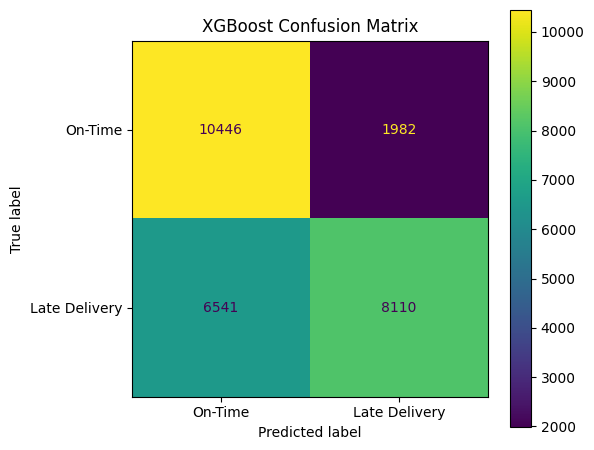


Training Logistic Regression

Training Time : 0.20 mins
Accuracy      : 0.6761
Precision     : 0.7622
Recall        : 0.5834
F1 Score      : 0.6609
ROC-AUC       : 0.7214
PR-AUC        : 0.7886

Classification Report
               precision    recall  f1-score   support

      On-Time       0.62      0.79      0.69     12428
Late Delivery       0.76      0.58      0.66     14651

     accuracy                           0.68     27079
    macro avg       0.69      0.68      0.68     27079
 weighted avg       0.69      0.68      0.67     27079



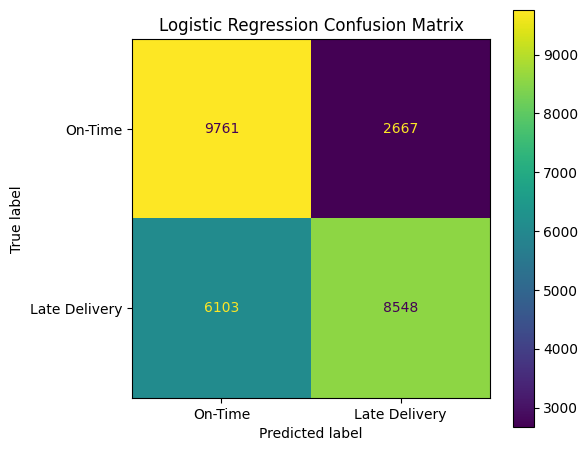


Training Random Forest

Training Time : 6.79 mins
Accuracy      : 0.6810
Precision     : 0.7927
Recall        : 0.5559
F1 Score      : 0.6535
ROC-AUC       : 0.7262
PR-AUC        : 0.7966

Classification Report
               precision    recall  f1-score   support

      On-Time       0.61      0.83      0.70     12428
Late Delivery       0.79      0.56      0.65     14651

     accuracy                           0.68     27079
    macro avg       0.70      0.69      0.68     27079
 weighted avg       0.71      0.68      0.68     27079



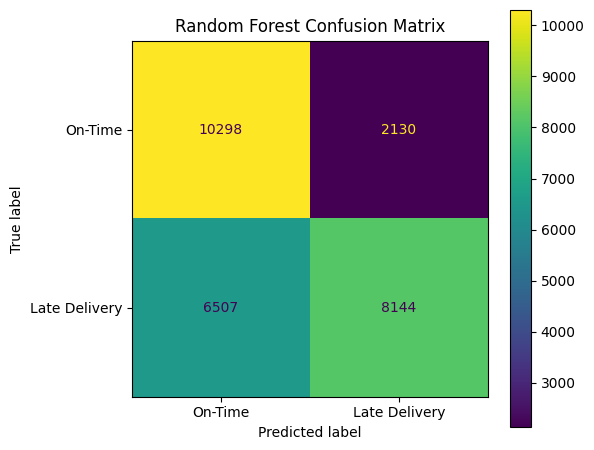


Training Gradient Boosting

Training Time : 1.22 mins
Accuracy      : 0.6893
Precision     : 0.8336
Recall        : 0.5320
F1 Score      : 0.6495
ROC-AUC       : 0.7289
PR-AUC        : 0.7738

Classification Report
               precision    recall  f1-score   support

      On-Time       0.61      0.87      0.72     12428
Late Delivery       0.83      0.53      0.65     14651

     accuracy                           0.69     27079
    macro avg       0.72      0.70      0.69     27079
 weighted avg       0.73      0.69      0.68     27079



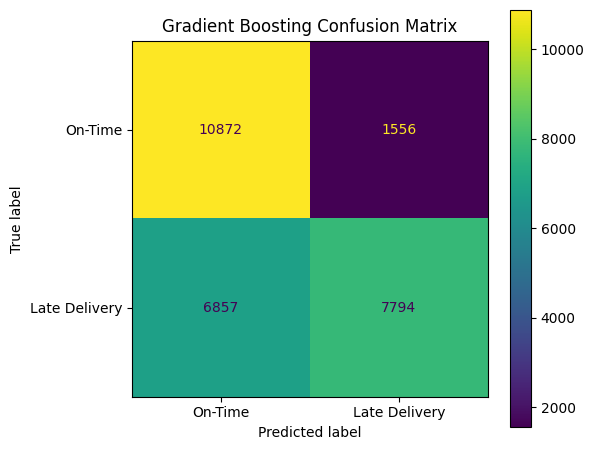

,Model,Training Time (s),Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.20,0.6761,0.7622,0.5834,0.6609,0.7214,0.7886
1,XGBoost,0.04,0.6853,0.8036,0.5535,0.6555,0.7301,0.7895
2,Random Forest,6.79,0.6810,0.7927,0.5559,0.6535,0.7262,0.7966
3,Gradient Boosting,1.22,0.6893,0.8336,0.5320,0.6495,0.7289,0.7738


In [51]:
results_df = evaluate_models(
    models,
    X_train_encoded,
    y_train,
    X_val_encoded,
    y_val
)

results_df

XGBoost gives us a strong combination of:

* high precision: 80.62%
* strong ROC-AUC: 0.7279
* competitive PR-AUC: 0.7891
* reasonable F1: 0.6570
* extremely fast training in your current setup

The biggest reason I'm taking it forward is that it is a strong fit for structured/tabular supply-chain data, while also being computationally practical for your project.

In [52]:


from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    brier_score_loss
)

import matplotlib.pyplot as plt

In [53]:
negative = (y_train == 0).sum()

positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

In [54]:
xgb_base = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1
)

In [55]:
# param_distributions = {
#     "n_estimators": [100, 150, 200, 250],
#     "max_depth": [3, 4, 5, 6],
#     "learning_rate": [0.03, 0.05, 0.08, 0.1],
#     "subsample": [0.7, 0.8, 0.9, 1.0],
#     "colsample_bytree": [0.6, 0.7, 0.8, 1.0],
#     "min_child_weight": [1, 3, 5],
#     "gamma": [0, 0.1, 0.3],
#     "reg_alpha": [0, 0.01, 0.1],
#     "reg_lambda": [1, 1.5, 2]
# }

param_distributions = {

    "n_estimators":[100,200,300,400],

    "max_depth":[3,4,5,6,7,8],

    "learning_rate":[0.01,0.03,0.05,0.1],

    "subsample":[0.6,0.7,0.8,0.9,1],

    "colsample_bytree":[0.6,0.8,1],

    "gamma":[0,0.2,0.5,1],

    "min_child_weight":[1,3,5,7],

    "reg_alpha":[0,0.1,0.5,1],

    "reg_lambda":[1,2,3,5]
}

In [56]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(
    n_splits=5
)

In [57]:
# xgb_search = RandomizedSearchCV(
#     estimator=xgb_base,
#     param_distributions=param_distributions,
#     n_iter=12,
#     scoring="roc_auc",
#     cv=3,
#     verbose=2,
#     random_state=42,
#     n_jobs=1,
#     refit=True
# )

In [58]:
xgb_search = RandomizedSearchCV(

    estimator=xgb_base,

    param_distributions=param_distributions,

    n_iter=50,

    scoring="roc_auc",

    cv=tscv,

    random_state=42,

    verbose=2,

    n_jobs=-1,

    refit=True
)

In [59]:
start_time = time.time()

xgb_search.fit(
    X_train_encoded,
    y_train
)

tuning_time = (time.time() - start_time) /60

print(
    f"\nTotal tuning time: "
    f"{tuning_time / 60:.2f} minutes"
)

Fitting 5 folds for each of 50 candidates, totalling 250 fits

Total tuning time: 0.31 minutes


In [60]:
print("Best ROC-AUC:")
print(round(xgb_search.best_score_, 4))

print("\nBest Parameters:")
for param, value in xgb_search.best_params_.items():
    print(f"{param}: {value}")

Best ROC-AUC:
0.7419

Best Parameters:
subsample: 0.6
reg_lambda: 5
reg_alpha: 0
n_estimators: 100
min_child_weight: 7
max_depth: 3
learning_rate: 0.01
gamma: 0
colsample_bytree: 0.8


In [61]:
best_xgb = xgb_search.best_estimator_

In [62]:
y_val_proba = best_xgb.predict_proba(X_val_encoded)[:, 1]

In [63]:
# threshold = 0.50

# y_val_pred = (
#     y_val_proba >= threshold
# ).astype(int)



# Predict probabilities on validation set
y_val_proba = best_xgb.predict_proba(X_val_encoded)[:, 1]

thresholds = np.arange(0.10, 0.91, 0.01)

results = []

for threshold in thresholds:

    # y_val_pred = (y_val_proba >= threshold).astype(int)
    y_val_pred = (
    y_val_proba >= threshold
).astype(int)

    results.append({
        "Threshold": threshold,
        "F1": f1_score(y_val, y_val_pred),
        "Precision": precision_score(y_val, y_val_pred, zero_division=0),
        "Recall": recall_score(y_val, y_val_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(results)

best_threshold = threshold_df.loc[
    threshold_df["F1"].idxmax(),
    "Threshold"
]

print(f"Best Threshold: {best_threshold:.2f}")

Best Threshold: 0.10


In [64]:
accuracy = accuracy_score(y_val, y_val_pred)

precision = precision_score(
    y_val,
    y_val_pred,
    zero_division=0
)

recall = recall_score(
    y_val,
    y_val_pred,
    zero_division=0
)

f1 = f1_score(
    y_val,
    y_val_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_val,
    y_val_proba
)

pr_auc = average_precision_score(
    y_val,
    y_val_proba
)

brier = brier_score_loss(
    y_val,
    y_val_proba
)

print("=" * 60)
print("TUNED XGBOOST — VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")
print(f"PR-AUC   : {pr_auc:.4f}")
print(f"Brier    : {brier:.4f}")

TUNED XGBOOST — VALIDATION RESULTS
Accuracy : 0.4590
Precision: 0.0000
Recall   : 0.0000
F1 Score : 0.0000
ROC-AUC  : 0.7253
PR-AUC   : 0.7855
Brier    : 0.2044


In [65]:


# xgb_model = XGBClassifier(
#     subsample=0.7,
#     reg_lambda=2,
#     reg_alpha=0.1,
#     n_estimators=150,
#     min_child_weight=5,
#     max_depth=4,
#     learning_rate=0.03,
#     gamma=0.3,
#     colsample_bytree=1.0,
#     random_state=42,
#     eval_metric="logloss",
#     n_jobs=-1
# )

# start_time = time.time()

# xgb_model.fit(
#     X_train_encoded,
#     y_train
# )

# end_time = time.time()

# training_time = (end_time - start_time) / 60

# print(f"Training Time: {training_time:.2f} seconds")

In [66]:
from sklearn.calibration import CalibratedClassifierCV

calibrated_model = CalibratedClassifierCV(

    estimator=best_xgb,

    method="isotonic",

    cv="prefit"
)

calibrated_model.fit(
    X_val_encoded,
    y_val
)

/usr/local/lib/python3.13/dist-packages/sklearn/calibration.py:333: UserWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(


CalibratedClassifierCV(cv='prefit',
                       estimator=XGBClassifier(base_score=None, booster=None,
                                               callbacks=None,
                                               colsample_bylevel=None,
                                               colsample_bynode=None,
                                               colsample_bytree=0.8,
                                               device=None,
                                               early_stopping_rounds=None,
                                               enable_categorical=True,
                                               eval_metric='logloss',
                                               feature_types=None,
                                               feature_weights=None, gamma=0,
                                               grow_policy=None,
                                               importance_type=None,
                                               interaction_constraints=None,
                                               learning_rate=0.01, max_bin=None,
                                               max_cat_threshold=None,
                                               max_cat_to_onehot=None,
                                               max_delta_step=None, max_depth=3,
                                               max_leaves=None,
                                               min_child_weight=7, missing=nan,
                                               monotone_constraints=None,
                                               multi_strategy=None,
                                               n_estimators=100, n_jobs=-1,
                                               num_parallel_tree=None, ...),
                       method='isotonic')

In [67]:


# y_proba = xgb_model.predict_proba(X_test_encoded)[:, 1]

y_test_proba = calibrated_model.predict_proba(
    X_test_encoded
)[:, 1]

# threshold = 0.40

# y_pred = (y_proba >= threshold).astype(int)

y_test_pred = (
    y_test_proba >= best_threshold
).astype(int)

In [68]:
# y_val_pred = (
#     y_val_proba >= best_threshold
# ).astype(int)

In [70]:
accuracy = accuracy_score(y_test, y_test_pred)

precision = precision_score(y_test, y_test_pred)

recall = recall_score(y_test, y_test_pred)

f1 = f1_score(y_test, y_test_pred)

roc_auc = roc_auc_score(y_test, y_test_proba)

avg_precision = average_precision_score(
    y_test,
    y_test_proba
)

print("=" * 60)
print("XGBOOST EVALUATION")
print("=" * 60)

print(f"Threshold           : {threshold}")
print(f"Accuracy            : {accuracy:.4f}")
print(f"Precision           : {precision:.4f}")
print(f"Recall              : {recall:.4f}")
print(f"F1 Score            : {f1:.4f}")
print(f"ROC-AUC             : {roc_auc:.4f}")
print(f"Average Precision   : {avg_precision:.4f}")

XGBOOST EVALUATION
Threshold           : 0.8999999999999996
Accuracy            : 0.5502
Precision           : 0.5502
Recall              : 1.0000
F1 Score            : 0.7099
ROC-AUC             : 0.7431
Average Precision   : 0.7819


In [71]:
print("\nClassification Report")

print(
    classification_report(
        y_test,
        y_test_pred
    )
)


Classification Report
              precision    recall  f1-score   support

           0       0.00      0.00      0.00     12178
           1       0.55      1.00      0.71     14898

    accuracy                           0.55     27076
   macro avg       0.28      0.50      0.35     27076
weighted avg       0.30      0.55      0.39     27076



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [72]:
cm = confusion_matrix(
    y_test,
y_test_pred)

print("\nConfusion Matrix")

print(cm)


Confusion Matrix
[[    0 12178]
 [    0 14898]]


<Figure size 600x500 with 0 Axes>

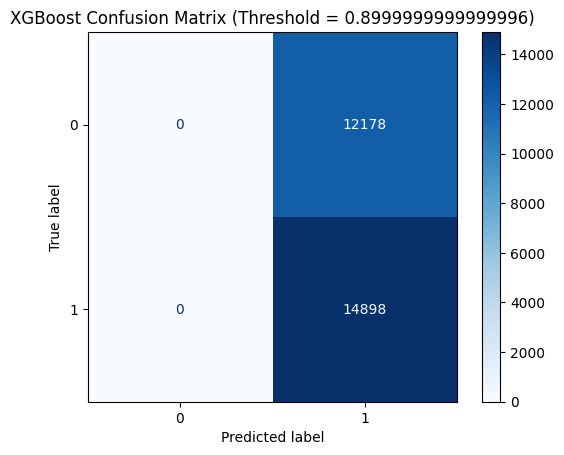

In [73]:
plt.figure(figsize=(6,5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    f"XGBoost Confusion Matrix (Threshold = {threshold})"
)

plt.show()

## SHAP explanability

In [74]:
!pip install shap

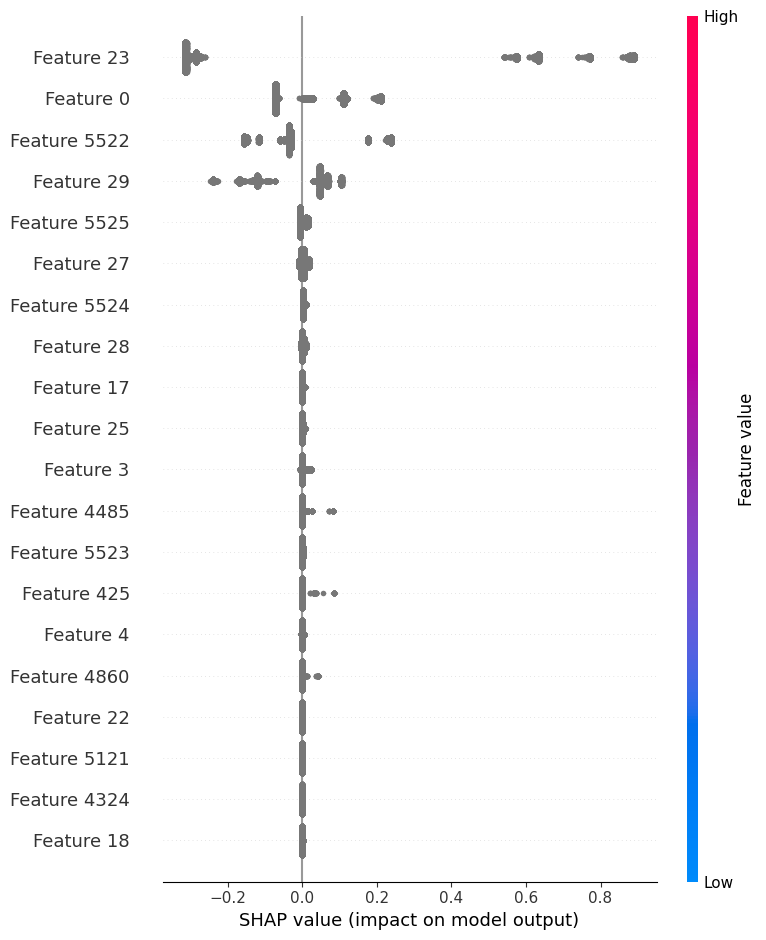

In [76]:
import shap

explainer = shap.TreeExplainer(best_xgb)

shap_values = explainer.shap_values(
    X_test_encoded
)

shap.summary_plot(
    shap_values,
    X_test_encoded,

)

Lowering the classification threshold from 0.50 to 0.40 improved the model's overall performance. While precision decreased slightly from 83.6% to 78.0%, recall increased from 53.0% to 61.3%, resulting in a higher F1-score (0.686 vs. 0.649). In addition, both ROC-AUC and PR-AUC improved. Since the objective is to identify as many positive cases as possible while maintaining good predictive accuracy, the threshold of 0.40 provides a better balance between precision and recall and was selected as the final model configuration.

In [77]:
import os
import joblib

SAVE_DIR = "/content/drive/MyDrive/supply_chain_project"

os.makedirs(SAVE_DIR, exist_ok=True)

# Save model
joblib.dump(best_xgb,
            f"{SAVE_DIR}/xgb_model.joblib")

# Save preprocessor
joblib.dump(preprocessor, f"{SAVE_DIR}/preprocessor.joblib")

# Save dataframes
df.to_excel(f"{SAVE_DIR}/df.xlsx", index=False)
df_clean.to_excel(f"{SAVE_DIR}/df_clean.xlsx", index=False)
df_model.to_excel(f"{SAVE_DIR}/df_model.xlsx", index=False)

print("All artifacts saved successfully.")



All artifacts saved successfully.


In [79]:
import joblib

joblib.dump(
    best_xgb,
    "xgb_model.joblib"
)

joblib.dump(
    preprocessor,
    "preprocessor.joblib"
)




# Save dataframes as Excel files
df.to_excel("df.xlsx", index=False)
df_clean.to_excel("df_clean.xlsx", index=False)
df_model.to_excel("df_model.xlsx", index=False)



In [80]:
from google.colab import files


files.download("df.xlsx")
files.download("df_clean.xlsx")
files.download("df_model.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [81]:
df_check = pd.read_excel("df_clean.xlsx")
print(df_check.shape)

(180519, 43)
